# PHẦN 2: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU CHUỖI THỜI GIAN (TIME SERIES EDA)

## 2.1. Mục tiêu phân tích

Phần này tập trung phân tích dữ liệu COVID-19 tại Bắc Mỹ (North America), châu Á (Asia) và châu Phi (Africa) theo thời gian.

Các mục tiêu chính bao gồm:

- Phân tích xu hướng số ca mắc mới COVID-19 hằng ngày.
- Sử dụng đường trung bình trượt 7 ngày và 14 ngày để làm rõ xu hướng.
- Phân tích tổng số ca xác nhận tích lũy.
- So sánh tình hình COVID-19 giữa ba châu lục.
- Xác định ngày có số ca mắc mới cao nhất trong giai đoạn nghiên cứu.
- Phân tích sự khác biệt về số ca mắc mới trung bình theo thứ trong tuần.

In [3]:
# ĐỌC DỮ LIỆU TỔNG HỢP

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đọc file CSV tổng hợp từ thư mục data
file_path = Path("../data/covid19_continent_daily_totals.csv")

df = pd.read_csv(file_path)

# Chuyển cột Date thành kiểu ngày tháng
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Sắp xếp dữ liệu theo châu lục và ngày
df = df.sort_values(
    ["Continent", "Date"]
).reset_index(drop=True)

# Hiển thị thông tin tổng quan
print("Kích thước dữ liệu:", df.shape)

print("\nDanh sách cột:")
print(df.columns.tolist())

print("\nNgày bắt đầu:", df["Date"].min())
print("Ngày kết thúc:", df["Date"].max())

print("\nSố bản ghi theo châu lục:")
print(df["Continent"].value_counts())

display(df.head())

Kích thước dữ liệu: (564, 12)

Danh sách cột:
['Date', 'Continent', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'New_Confirmed', 'New_Deaths', 'New_Recovered', 'Rolling_7D_New_Confirmed', 'Rolling_14D_New_Confirmed', 'Cumulative_Confirmed_Total']

Ngày bắt đầu: 2020-01-22 00:00:00
Ngày kết thúc: 2020-07-27 00:00:00

Số bản ghi theo châu lục:
Continent
Africa           188
Asia             188
North America    188
Name: count, dtype: int64


,Date,Continent,Confirmed,Deaths,Recovered,Active,New_Confirmed,New_Deaths,New_Recovered,Rolling_7D_New_Confirmed,Rolling_14D_New_Confirmed,Cumulative_Confirmed_Total
0,2020-01-22,Africa,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
1,2020-01-23,Africa,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
2,2020-01-24,Africa,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
3,2020-01-25,Africa,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
4,2020-01-26,Africa,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0


In [4]:
# KIỂM TRA CÁC CỘT CẦN THIẾT

print("Số dòng:", len(df))
print("Số giá trị Date không hợp lệ:", df["Date"].isna().sum())
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

print("\nGiá trị thiếu theo cột:")
print(df.isnull().sum())

# Kiểm tra các cột cần thiết cho phân tích
required_columns = [
    "Date",
    "Continent",
    "New_Confirmed",
    "Confirmed",
    "Deaths",
    "Recovered"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("\nCác cột chưa có trong dữ liệu:", missing_columns)
else:
    print("\nĐã có đủ các cột cần thiết.")

Số dòng: 564
Số giá trị Date không hợp lệ: 0
Số dòng trùng hoàn toàn: 0

Giá trị thiếu theo cột:
Date                          0
Continent                     0
Confirmed                     0
Deaths                        0
Recovered                     0
Active                        0
New_Confirmed                 0
New_Deaths                    0
New_Recovered                 0
Rolling_7D_New_Confirmed      0
Rolling_14D_New_Confirmed     0
Cumulative_Confirmed_Total    0
dtype: int64

Đã có đủ các cột cần thiết.


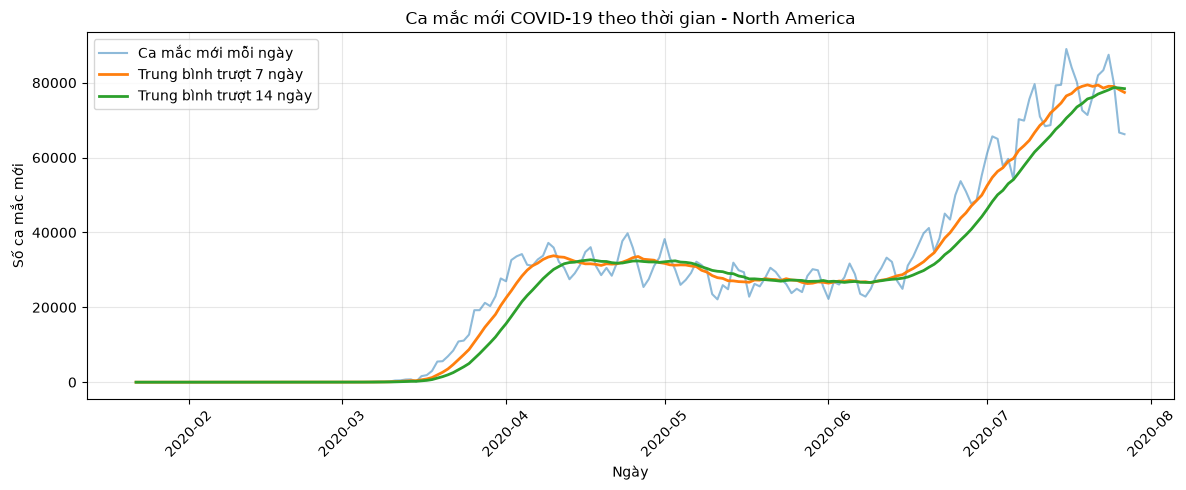

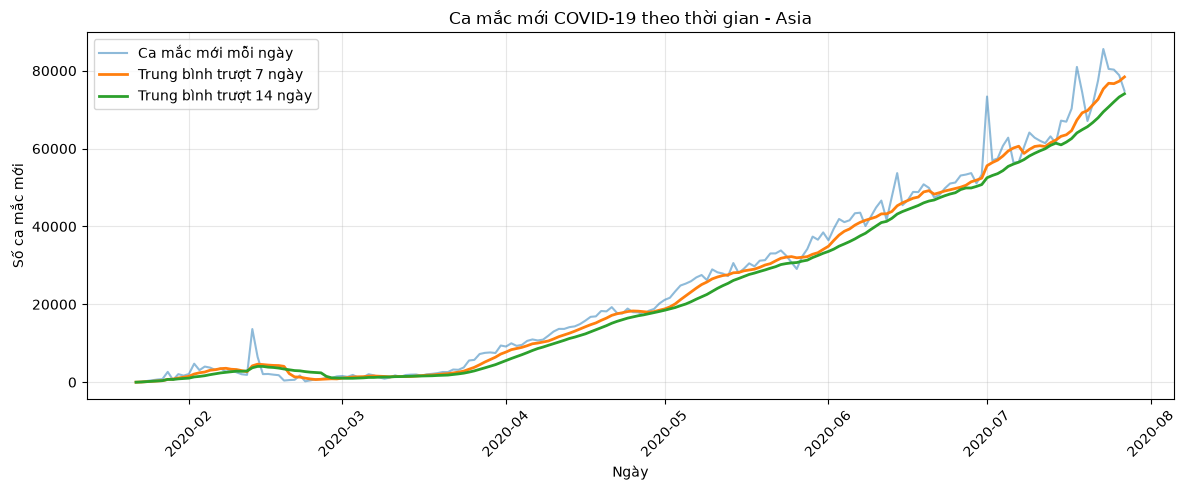

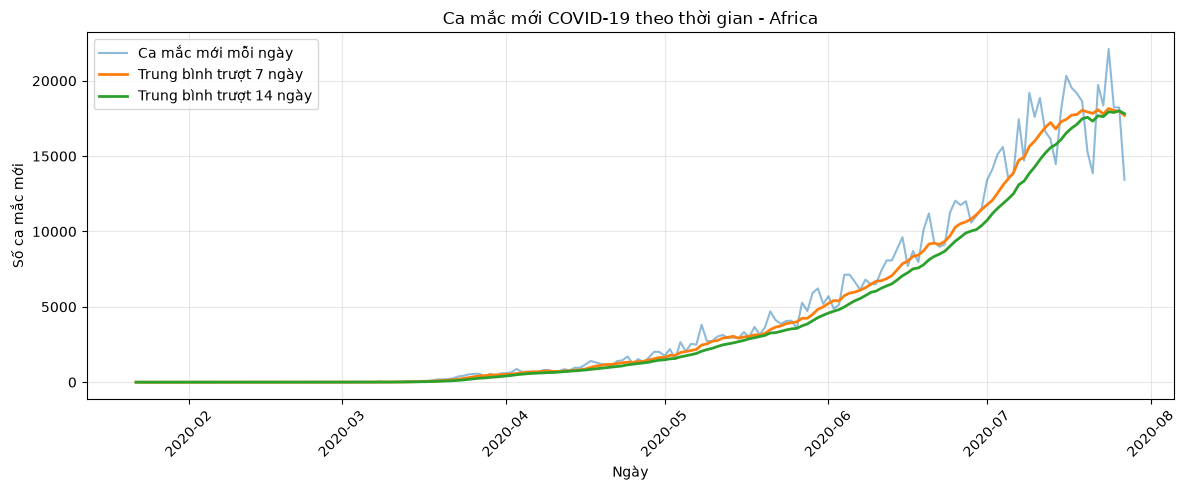

In [5]:
# BIỂU ĐỒ CA MẮC MỚI VÀ TRUNG BÌNH TRƯỢT

continents = [
    "North America",
    "Asia",
    "Africa"
]

for continent in continents:

    temp = df[
        df["Continent"] == continent
    ].sort_values("Date").copy()

    plt.figure(figsize=(12, 5))

    plt.plot(
        temp["Date"],
        temp["New_Confirmed"],
        label="Ca mắc mới mỗi ngày",
        alpha=0.5
    )

    plt.plot(
        temp["Date"],
        temp["Rolling_7D_New_Confirmed"],
        label="Trung bình trượt 7 ngày",
        linewidth=2
    )

    plt.plot(
        temp["Date"],
        temp["Rolling_14D_New_Confirmed"],
        label="Trung bình trượt 14 ngày",
        linewidth=2
    )

    plt.title(
        f"Ca mắc mới COVID-19 theo thời gian - {continent}"
    )

    plt.xlabel("Ngày")
    plt.ylabel("Số ca mắc mới")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

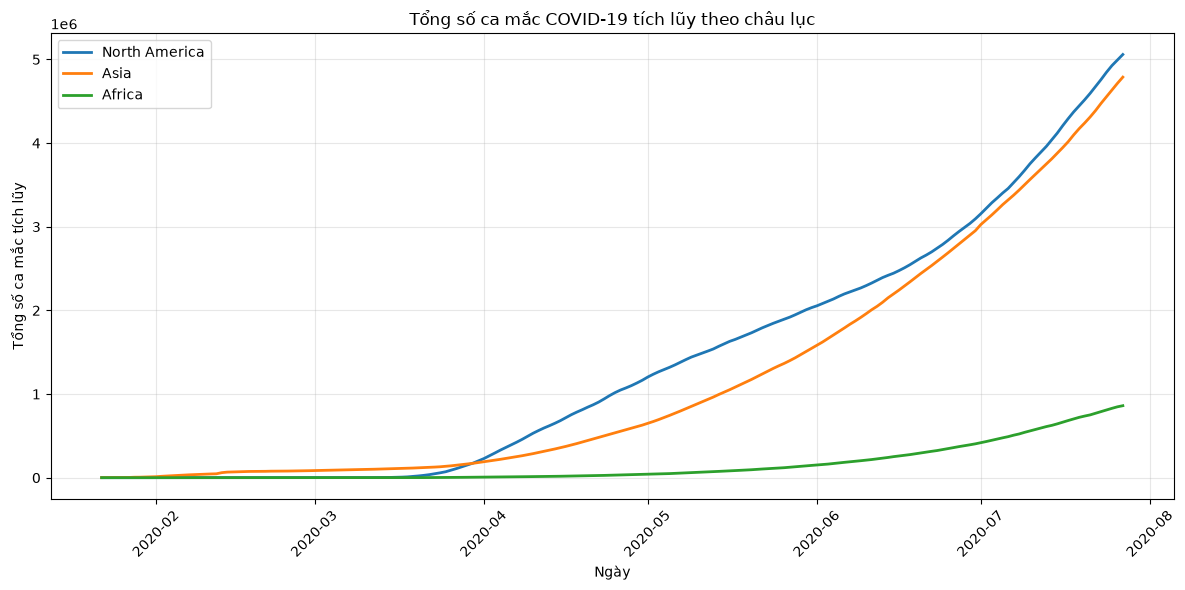

In [6]:
# Vẽ biểu đồ tổng số ca mắc tích lũy
continents = ["North America", "Asia", "Africa"]

plt.figure(figsize=(12, 6))

for continent in continents:
    temp = df[df["Continent"] == continent].sort_values("Date")

    plt.plot(
        temp["Date"],
        temp["Confirmed"],
        label=continent,
        linewidth=2
    )

plt.title("Tổng số ca mắc COVID-19 tích lũy theo châu lục")
plt.xlabel("Ngày")
plt.ylabel("Tổng số ca mắc tích lũy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
# So sánh dữ liệu cuối kỳ
latest_date = df["Date"].max()

latest_data = (
    df[df["Date"] == latest_date]
    [["Continent", "Confirmed", "Deaths", "Recovered"]]
    .sort_values("Confirmed", ascending=False)
)

print("Ngày thống kê:", latest_date.strftime("%Y-%m-%d"))
display(latest_data)

Ngày thống kê: 2020-07-27


,Continent,Confirmed,Deaths,Recovered
563,North America,5058816,207226,1754456
375,Asia,4788295,104469,3473508
187,Africa,860537,18176,506229


In [8]:
# Tìm ngày có số ca mắc mới cao nhất của từng châu lục

peak_results = []

for continent in ["North America", "Asia", "Africa"]:
    temp = df[df["Continent"] == continent].copy()

    peak_index = temp["New_Confirmed"].idxmax()
    peak_row = temp.loc[peak_index]

    peak_results.append({
        "Continent": continent,
        "Peak_Date": peak_row["Date"].strftime("%Y-%m-%d"),
        "Peak_New_Confirmed": int(peak_row["New_Confirmed"])
    })

peak_df = pd.DataFrame(peak_results)

display(peak_df)

,Continent,Peak_Date,Peak_New_Confirmed
0,North America,2020-07-16,89010
1,Asia,2020-07-23,85583
2,Africa,2020-07-24,22111


In [9]:
# Phân tích số ca mắc mới theo thứ trong tuần
#Tạo cột thứ trong tuần
# Tạo cột thứ trong tuần
df["Weekday"] = df["Date"].dt.day_name()

# Sắp xếp thứ theo thứ tự từ thứ Hai đến Chủ nhật
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_vietnamese = {
    "Monday": "Thứ Hai",
    "Tuesday": "Thứ Ba",
    "Wednesday": "Thứ Tư",
    "Thursday": "Thứ Năm",
    "Friday": "Thứ Sáu",
    "Saturday": "Thứ Bảy",
    "Sunday": "Chủ nhật"
}

In [10]:
# Tính số ca mắc mới trung bình theo thứ
weekday_avg = df.groupby(
    ["Continent", "Weekday"]
)["New_Confirmed"].mean().reset_index()

weekday_avg["Weekday"] = pd.Categorical(
    weekday_avg["Weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_avg = weekday_avg.sort_values(
    ["Continent", "Weekday"]
)

weekday_avg["Weekday"] = (
    weekday_avg["Weekday"].astype(str).map(weekday_vietnamese)
)

display(weekday_avg)

,Continent,Weekday,New_Confirmed
1,Africa,Thứ Hai,4414.370370
5,Africa,Thứ Ba,3955.576923
6,Africa,Thứ Tư,4384.888889
4,Africa,Thứ Năm,4750.481481
0,Africa,Thứ Sáu,5017.333333
2,Africa,Thứ Bảy,4915.296296
3,Africa,Chủ nhật,4580.296296
8,Asia,Thứ Hai,25197.000000
12,Asia,Thứ Ba,24110.461538
13,Asia,Thứ Tư,24874.888889


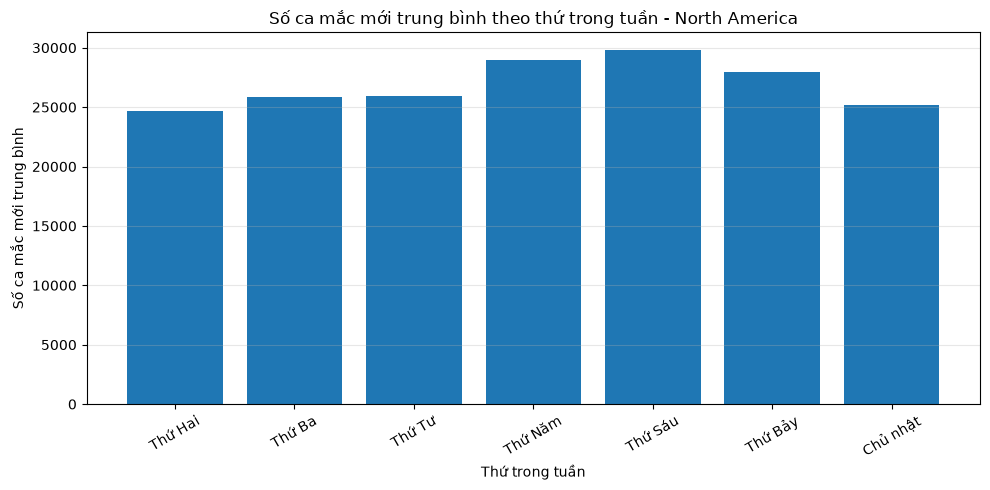

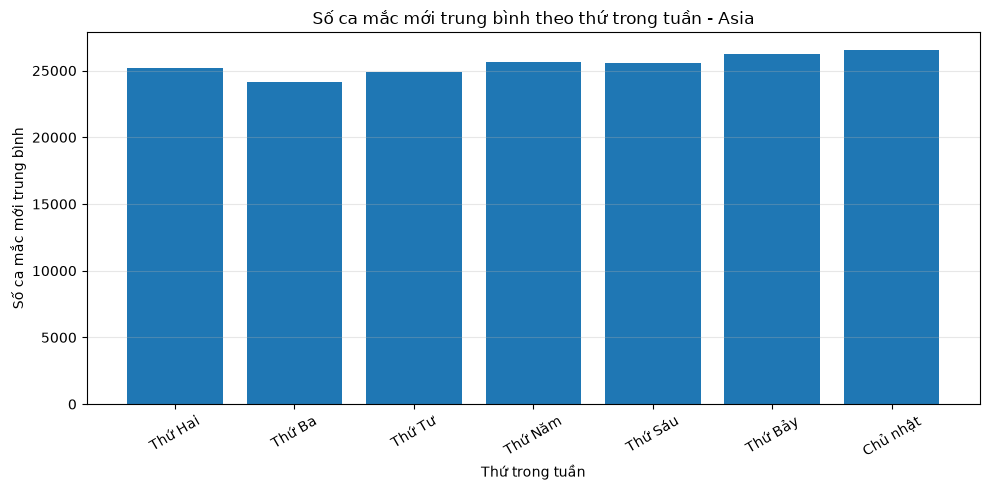

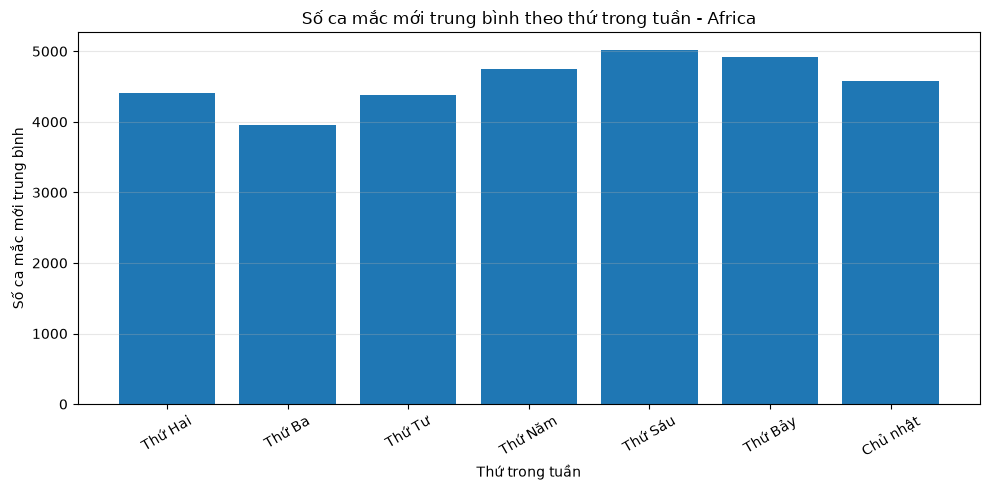

In [11]:
# Vẽ biểu đồ so sánh
for continent in ["North America", "Asia", "Africa"]:
    temp = weekday_avg[
        weekday_avg["Continent"] == continent
    ]

    plt.figure(figsize=(10, 5))

    plt.bar(
        temp["Weekday"],
        temp["New_Confirmed"]
    )

    plt.title(
        f"Số ca mắc mới trung bình theo thứ trong tuần - {continent}"
    )
    plt.xlabel("Thứ trong tuần")
    plt.ylabel("Số ca mắc mới trung bình")
    plt.xticks(rotation=30)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [12]:
# Kiểm tra dữ liệu ngày theo từng châu lục

for continent in ["North America", "Asia", "Africa"]:
    temp = (
        df[df["Continent"] == continent]
        .sort_values("Date")
    )

    date_diff = temp["Date"].diff().dt.days

    print(f"\n--- {continent} ---")
    print("Số bản ghi:", len(temp))
    print("Ngày bắt đầu:", temp["Date"].min())
    print("Ngày kết thúc:", temp["Date"].max())
    print("Số khoảng cách ngày lớn hơn 1:",
          (date_diff > 1).sum())


--- North America ---
Số bản ghi: 188
Ngày bắt đầu: 2020-01-22 00:00:00
Ngày kết thúc: 2020-07-27 00:00:00
Số khoảng cách ngày lớn hơn 1: 0

--- Asia ---
Số bản ghi: 188
Ngày bắt đầu: 2020-01-22 00:00:00
Ngày kết thúc: 2020-07-27 00:00:00
Số khoảng cách ngày lớn hơn 1: 0

--- Africa ---
Số bản ghi: 188
Ngày bắt đầu: 2020-01-22 00:00:00
Ngày kết thúc: 2020-07-27 00:00:00
Số khoảng cách ngày lớn hơn 1: 0


In [13]:
# Kiểm tra giá trị âm trong các cột số ca hằng ngày

daily_columns = [
    "New_Confirmed",
    "New_Deaths",
    "New_Recovered"
]

for col in daily_columns:
    if col in df.columns:
        print(f"\nCột: {col}")
        print("Số giá trị âm:", (df[col] < 0).sum())
        print("Số giá trị thiếu:", df[col].isna().sum())


Cột: New_Confirmed
Số giá trị âm: 0
Số giá trị thiếu: 0

Cột: New_Deaths
Số giá trị âm: 0
Số giá trị thiếu: 0

Cột: New_Recovered
Số giá trị âm: 4
Số giá trị thiếu: 0


In [14]:
# Tìm các dòng có số ca hồi phục âm
negative_recovered = df[df["New_Recovered"] < 0].copy()

display(
    negative_recovered[
        ["Date", "Continent", "Recovered", "New_Recovered"]
    ].sort_values(["Continent", "Date"])
)

,Date,Continent,Recovered,New_Recovered
53,2020-03-15,Africa,35,-6.0
62,2020-03-24,Africa,137,-6.0
64,2020-03-26,Africa,184,-27.0
555,2020-07-19,North America,1486137,-6055.0


In [15]:
# Kiểm tra dữ liệu hồi phục của các ngày xung quanh giá trị âm

for _, row in negative_recovered.iterrows():
    continent = row["Continent"]
    date = row["Date"]

    temp = df[
        (df["Continent"] == continent) &
        (df["Date"].between(
            date - pd.Timedelta(days=2),
            date + pd.Timedelta(days=2)
        ))
    ].sort_values("Date")

    print(f"\n--- {continent} | {date.strftime('%Y-%m-%d')} ---")
    display(temp[["Date", "Recovered", "New_Recovered"]])


--- Africa | 2020-03-15 ---


,Date,Recovered,New_Recovered
51,2020-03-13,37,1.0
52,2020-03-14,41,4.0
53,2020-03-15,35,-6.0
54,2020-03-16,42,7.0
55,2020-03-17,48,6.0



--- Africa | 2020-03-24 ---


,Date,Recovered,New_Recovered
60,2020-03-22,143,54.0
61,2020-03-23,143,0.0
62,2020-03-24,137,-6.0
63,2020-03-25,211,74.0
64,2020-03-26,184,-27.0



--- Africa | 2020-03-26 ---


,Date,Recovered,New_Recovered
62,2020-03-24,137,-6.0
63,2020-03-25,211,74.0
64,2020-03-26,184,-27.0
65,2020-03-27,229,45.0
66,2020-03-28,253,24.0



--- North America | 2020-07-19 ---


,Date,Recovered,New_Recovered
553,2020-07-17,1449643,25361.0
554,2020-07-18,1492192,42549.0
555,2020-07-19,1486137,-6055.0
556,2020-07-20,1526872,40735.0
557,2020-07-21,1556583,29711.0


# KẾT QUẢ PHẦN 2 — TIME SERIES EDA

## 1. Phân tích xu hướng ca mắc mới

Nghiên cứu sử dụng dữ liệu COVID-19 của ba khu vực: Bắc Mỹ, châu Á và châu Phi trong giai đoạn từ ngày 22/01/2020 đến ngày 27/07/2020.

Các biểu đồ chuỗi thời gian được xây dựng để thể hiện số ca mắc mới hằng ngày, kết hợp với đường trung bình trượt 7 ngày và 14 ngày nhằm làm rõ xu hướng biến động.

Kết quả trực quan cho thấy số ca mắc mới có xu hướng tăng ở cả ba châu lục trong giai đoạn quan sát. Bắc Mỹ và châu Á ghi nhận mức ca mắc mới hằng ngày cao hơn châu Phi trong các biểu đồ.

## 2. So sánh số ca mắc tích lũy và số liệu cuối kỳ

Tại ngày 27/07/2020, dữ liệu ghi nhận:

- **Bắc Mỹ:** 5.058.816 ca mắc, 207.226 ca tử vong và 1.754.456 ca hồi phục.
- **Châu Á:** 4.788.295 ca mắc, 104.469 ca tử vong và 3.473.508 ca hồi phục.
- **Châu Phi:** 860.537 ca mắc, 18.176 ca tử vong và 506.229 ca hồi phục.

Bắc Mỹ có tổng số ca mắc và tử vong cao nhất trong ba châu lục. Châu Á có số ca hồi phục cao nhất tại thời điểm thống kê.

## 3. Phân tích ngày đạt đỉnh số ca mắc mới

Kết quả xác định ngày có số ca mắc mới cao nhất trong khoảng thời gian dữ liệu:

- **Bắc Mỹ:** Ngày 16/07/2020, với 89.010 ca.
- **Châu Á:** Ngày 23/07/2020, với 85.583 ca.
- **Châu Phi:** Ngày 24/07/2020, với 22.111 ca.

Các đỉnh số ca mắc mới được ghi nhận vào nửa cuối tháng 7/2020, nhưng mức đỉnh khác nhau giữa các khu vực.

## 4. Phân tích số ca mắc mới theo thứ trong tuần

Kết quả phân tích số ca mắc mới trung bình theo thứ trong tuần cho thấy sự khác biệt giữa ba châu lục.

**Bắc Mỹ (North America):** Số ca mắc mới trung bình cao nhất vào thứ Năm, đạt khoảng 28.987,70 ca/ngày. Thứ Hai có mức trung bình thấp nhất, khoảng 24.660,33 ca/ngày.

**Châu Á (Asia):** Chủ nhật có số ca mắc mới trung bình cao nhất, khoảng 26.542,74 ca/ngày. Thứ Ba có mức trung bình thấp nhất, khoảng 24.110,46 ca/ngày.

**Châu Phi (Africa):** Thứ Sáu có số ca mắc mới trung bình cao nhất, khoảng 5.017,33 ca/ngày. Thứ Ba có mức trung bình thấp nhất, khoảng 3.955,58 ca/ngày.

Nhìn chung, Bắc Mỹ có số ca mắc mới trung bình cao nhất vào thứ Năm, trong khi châu Á đạt mức cao nhất vào Chủ nhật và châu Phi đạt mức cao nhất vào thứ Sáu. Kết quả này mô tả sự khác biệt giữa các ngày trong tuần trong giai đoạn nghiên cứu. Tuy nhiên, chưa thể khẳng định thứ trong tuần là nguyên nhân gây ra sự khác biệt này.

## 5. Đánh giá chất lượng dữ liệu

Dữ liệu tổng hợp có 564 bản ghi, gồm 188 bản ghi cho mỗi châu lục, trong khoảng thời gian từ ngày 22/01/2020 đến ngày 27/07/2020.

Kết quả kiểm tra cho thấy:

- Không phát hiện dòng trùng hoàn toàn.
- Không phát hiện giá trị thiếu trong các cột đã kiểm tra.
- Không phát hiện khoảng trống ngày giữa các bản ghi liên tiếp của từng châu lục.
- Không có giá trị âm trong `New_Confirmed` và `New_Deaths`.
- Có 4 giá trị âm trong `New_Recovered`, gồm 3 giá trị tại châu Phi và 1 giá trị tại Bắc Mỹ.

Các giá trị âm trong `New_Recovered` được ghi nhận là những trường hợp cần lưu ý. Chúng chưa được tự động thay thế hoặc xóa khi chưa xác định rõ nguyên nhân.

## 6. Kết luận

Phân tích chuỗi thời gian đã làm rõ xu hướng biến động của số ca mắc mới COVID-19 tại Bắc Mỹ, châu Á và châu Phi trong giai đoạn nghiên cứu. Các biểu đồ trung bình trượt hỗ trợ nhận diện xu hướng, trong khi bảng thống kê và phân tích đỉnh dịch giúp so sánh mức độ biến động giữa các khu vực.

Kết quả kiểm tra chất lượng dữ liệu cho thấy dữ liệu có tính liên tục về thời gian và không có giá trị thiếu trong các cột đã kiểm tra. Tuy nhiên, các giá trị âm trong `New_Recovered` cần được lưu ý trong những bước phân tích tiếp theo.